# C.R.A.T.E.R. - Person A: Onboard Perception (classical CV)
Pipeline: **CLAHE -> blur -> adaptive threshold -> morphology -> contours -> rule-based classifier**.
CPU only, no cloud, no training. Output format per detection:
`{frame_id, class_id, pixel_x, pixel_y, confidence}` (pixel = bottom-centre of the box = ground contact point).

Classes: `0 = rock`, `1 = pit/crater`, `2 = bright patch (ice candidate)`.

**Kaggle setup:** Add data -> search `artificial-lunar-rocky-landscape-dataset` (by romainpessia).

In [1]:
import os, glob, json, time
import numpy as np
import cv2
import psutil
import matplotlib.pyplot as plt

DATA_ROOT = "/kaggle/input"          # change to your local folder if not on Kaggle
N_IMAGES  = 200                      # how many images to use
TARGET_W  = 640                      # downscale width (speed vs accuracy knob)

# auto-discover rendered images (works even if the folder layout differs slightly)
imgs = sorted(glob.glob(f"{DATA_ROOT}/**/render*.png", recursive=True))
if not imgs:   # fallback: any png/jpg
    imgs = sorted(glob.glob(f"{DATA_ROOT}/**/*.png", recursive=True) +
                  glob.glob(f"{DATA_ROOT}/**/*.jpg", recursive=True))
imgs = imgs[:N_IMAGES]
print(len(imgs), "images found")
print(imgs[:3])

200 images found
['/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/images/render/render0001.png', '/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/images/render/render0002.png', '/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/images/render/render0003.png']


In [2]:
import glob, collections
print(glob.glob("/kaggle/input/datasets/*/*"))   # which datasets are attached

def owner(p): return p.split("/")[4]             # romainpessia or vatsal1729
print(collections.Counter(owner(p) for p in imgs))   # what the 200 images came from

# how many render*.png each dataset has in total
allr = glob.glob("/kaggle/input/**/render*.png", recursive=True)
print(collections.Counter(owner(p) for p in allr))

['/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset', '/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset']
Counter({'romainpessia': 200})
Counter({'romainpessia': 9766, 'vatsal1729': 1953})


In [3]:
!find /kaggle/input/datasets/vatsal1729 -maxdepth 3 | head -30

/kaggle/input/datasets/vatsal1729
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground1149.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground4812.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground6854.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground3304.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground5947.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground6928.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground1870.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground1340.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground0018.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-dataset/ground/ground4259.png
/kaggle/input/datasets/vatsal1729/filtered-lunar-datase

In [4]:
def ids(ds):
    return {os.path.basename(p) for p in allr if owner(p) == ds}
a, b = ids("romainpessia"), ids("vatsal1729")
print(len(b & a), "of", len(b), "filtered images also exist in the original")

1953 of 1953 filtered images also exist in the original


In [5]:
good = ids("vatsal1729")
imgs = [p for p in sorted(glob.glob("/kaggle/input/datasets/romainpessia/**/render*.png", recursive=True))
        if os.path.basename(p) in good][:N_IMAGES]
print(len(imgs), "curated images")

200 curated images


In [6]:
CLASS_NAMES = {0: "rock", 1: "pit", 2: "bright"}
CLASS_COLORS = {0: (0, 255, 0), 1: (0, 0, 255), 2: (255, 255, 0)}
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def find_horizon(gray):
    """First row whose mean brightness is above a floor = start of terrain (sky is near-black)."""
    rows = gray.mean(axis=1)
    rows = np.convolve(rows, np.ones(9) / 9, mode="same")
    idx = np.where(rows > 15)[0]
    return int(idx[0]) if len(idx) else 0

def detect(frame_bgr, frame_id=0, min_area_frac=0.0005, max_area_frac=0.25):
    """Return list of dicts: frame_id, class_id, pixel_x, pixel_y, confidence, bbox."""
    h, w = frame_bgr.shape[:2]
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    horizon = find_horizon(gray)

    g = clahe.apply(gray)
    g = cv2.GaussianBlur(g, (5, 5), 0)

    dark   = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 8)
    bright = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, -8)
    mask = cv2.bitwise_or(dark, bright)
    mask[:horizon, :] = 0                                    # ignore sky
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL, iterations=2)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    frame_area = float(h * w)
    ground_mean = gray[horizon:, :].mean() if horizon < h else gray.mean()
    out = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < min_area_frac * frame_area or area > max_area_frac * frame_area:
            continue
        per = cv2.arcLength(c, True)
        if per == 0:
            continue
        circ = 4 * np.pi * area / (per * per)
        hull_area = cv2.contourArea(cv2.convexHull(c))
        solidity = area / hull_area if hull_area > 0 else 0
        x, y, bw, bh = cv2.boundingRect(c)
        blob = np.zeros((h, w), np.uint8)
        cv2.drawContours(blob, [c], -1, 255, -1)
        mean_int = cv2.mean(gray, mask=blob)[0]

        if mean_int > 200 and solidity > 0.8:
            cls = 2                                           # bright patch (ice candidate)
        elif circ > 0.75 and area > 0.01 * frame_area and mean_int < 0.7 * ground_mean:
            cls = 1                                           # dark round region (pit)
        else:
            cls = 0                                           # rock
        conf = float(min(1.0, 0.5 * solidity + 0.5 * min(area / (0.02 * frame_area), 1.0)))  # heuristic
        out.append({"frame_id": frame_id, "class_id": cls,
                    "pixel_x": float(x + bw / 2), "pixel_y": float(y + bh),   # bottom-centre
                    "confidence": round(conf, 3), "bbox": (x, y, bw, bh)})
    return out

def load(path, width=TARGET_W):
    im = cv2.imread(path)
    if im is None:
        raise IOError(path)
    s = width / im.shape[1]
    return cv2.resize(im, (width, int(im.shape[0] * s)), interpolation=cv2.INTER_AREA)

def draw(frame, dets):
    vis = frame.copy()
    for d in dets:
        x, y, bw, bh = d["bbox"]
        col = CLASS_COLORS[d["class_id"]]
        cv2.rectangle(vis, (x, y), (x + bw, y + bh), col, 1)
        cv2.circle(vis, (int(d["pixel_x"]), int(d["pixel_y"])), 3, (0, 0, 255), -1)
    return vis

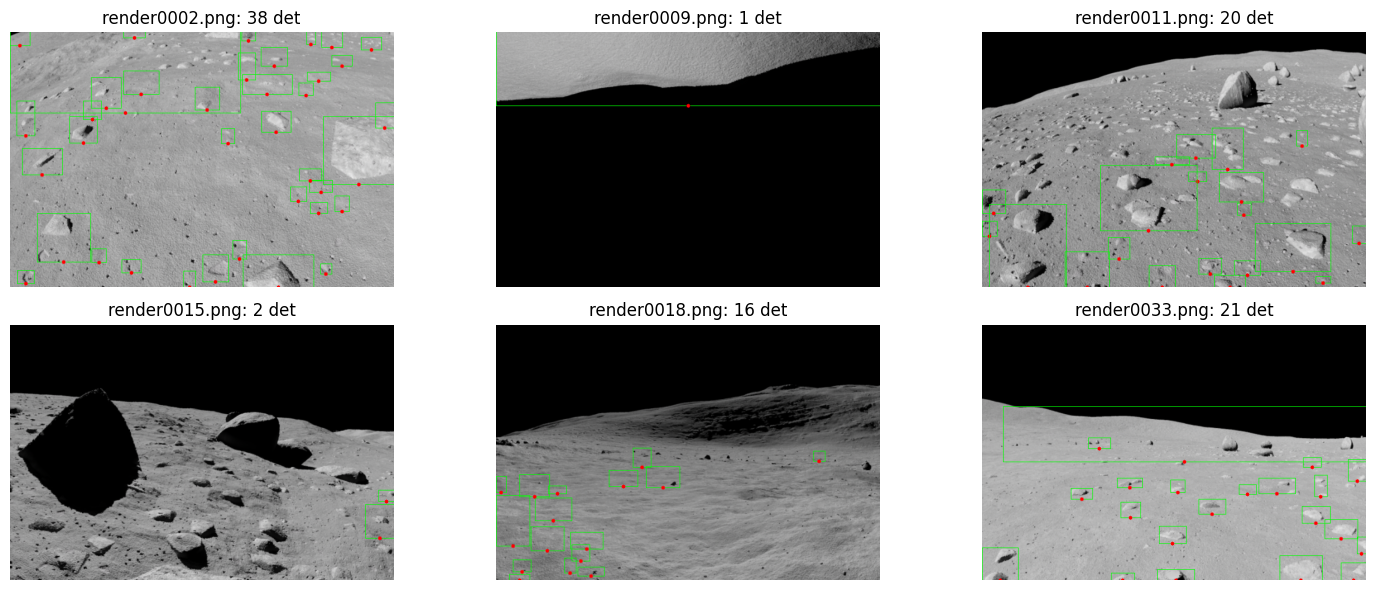

In [7]:
# Visual check on 6 images
sel = imgs[:6]
fig, axs = plt.subplots(2, 3, figsize=(15, 6))
for ax, p in zip(axs.ravel(), sel):
    f = load(p)
    dets = detect(f)
    ax.imshow(cv2.cvtColor(draw(f, dets), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{os.path.basename(p)}: {len(dets)} det")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [8]:
# Benchmark: FPS, latency, CPU %, RAM  -> goes in the 'Edge Perception Efficiency' score
proc = psutil.Process(os.getpid())
frames = [load(p) for p in imgs[:100]]          # preload so we time detection, not disk I/O
proc.cpu_percent(None)
lat = []
t_all = time.perf_counter()
for i, f in enumerate(frames):
    t0 = time.perf_counter()
    detect(f, frame_id=i)
    lat.append((time.perf_counter() - t0) * 1000)
total = time.perf_counter() - t_all
metrics = {
    "frames": len(frames),
    "resolution": f"{frames[0].shape[1]}x{frames[0].shape[0]}",
    "avg_latency_ms": round(float(np.mean(lat)), 2),
    "p95_latency_ms": round(float(np.percentile(lat, 95)), 2),
    "fps": round(len(frames) / total, 1),
    "cpu_percent_process": proc.cpu_percent(None),
    "ram_mb": round(proc.memory_info().rss / 1e6, 1),
    "device": "CPU only, no cloud",
}
print(json.dumps(metrics, indent=2))
os.makedirs("/kaggle/working", exist_ok=True)
with open("perception_metrics.json", "w") as fh:
    json.dump(metrics, fh, indent=2)

{
  "frames": 100,
  "resolution": "640x426",
  "avg_latency_ms": 9.99,
  "p95_latency_ms": 12.13,
  "fps": 100.0,
  "cpu_percent_process": 252.1,
  "ram_mb": 245.8,
  "device": "CPU only, no cloud"
}


In [9]:
# FPS vs resolution trade-off (good pitch slide)
rows = []
raw = [cv2.imread(p) for p in imgs[:30]]
for wdt in (320, 480, 640, 960):
    fs = [cv2.resize(r, (wdt, int(r.shape[0] * wdt / r.shape[1]))) for r in raw]
    t0 = time.perf_counter()
    n = 0
    for i, f in enumerate(fs):
        n += len(detect(f, i))
    fps = len(fs) / (time.perf_counter() - t0)
    rows.append((wdt, round(fps, 1), round(n / len(fs), 1)))
print("width | FPS | avg detections/frame")
for r in rows:
    print(r)

width | FPS | avg detections/frame
(320, 302.9, 11.2)
(480, 159.1, 13.9)
(640, 102.7, 15.8)
(960, 49.5, 20.2)


In [10]:
# OPTIONAL accuracy check vs the dataset's bounding-box table (large rocks).
# The CSV layout may differ: inspect it, then set the column names below.
csvs = glob.glob(f"{DATA_ROOT}/**/*.csv", recursive=True)
print(csvs)
if csvs:
    import pandas as pd
    df = pd.read_csv(csvs[0])
    print(df.head())
    print(df.columns.tolist())

['/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/bounding_boxes.csv', '/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/real_moon_images/PCAM_bounding_boxes.csv', '/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset/real_moon_images/TCAM_bounding_boxes.csv']
   Frame  TopLeftCornerX  TopLeftCornerY  Length  Height
0      1           278.5           192.5      56      38
1      2           599.5           151.5     121     130
2      3             5.5            46.5      90      87
3      5           239.5           101.5     103      21
4      6           682.5           124.5      34      26
['Frame', 'TopLeftCornerX', 'TopLeftCornerY', 'Length', 'Height']


In [11]:
# Set these after reading the printout above; leave None to skip.
IMG_COL = None    # column holding the image id/name, e.g. "Image"
X1, Y1, X2, Y2 = None, None, None, None   # box columns in ORIGINAL image pixels

def iou(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    iw = max(0, min(ax2, bx2) - max(ax1, bx1)); ih = max(0, min(ay2, by2) - max(ay1, by1))
    inter = iw * ih
    u = (ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - inter
    return inter / u if u > 0 else 0

if csvs and IMG_COL and X1:
    hit = tot = 0; preds_total = 0
    for p in imgs[:50]:
        key = os.path.splitext(os.path.basename(p))[0]
        sub = df[df[IMG_COL].astype(str).str.contains(key.replace("render", ""), regex=False)]
        if sub.empty:
            continue
        orig = cv2.imread(p); sc = TARGET_W / orig.shape[1]
        dets = detect(load(p))
        preds = [(d["bbox"][0], d["bbox"][1], d["bbox"][0] + d["bbox"][2], d["bbox"][1] + d["bbox"][3]) for d in dets]
        preds_total += len(preds)
        for _, r in sub.iterrows():
            gt = (r[X1] * sc, r[Y1] * sc, r[X2] * sc, r[Y2] * sc)
            tot += 1
            hit += any(iou(gt, pr) > 0.3 for pr in preds)
    print(f"recall@IoU0.3 = {hit}/{tot} = {hit / max(tot, 1):.2f}   (predictions: {preds_total})")
else:
    print("Skipping accuracy check - set the column names first.")

Skipping accuracy check - set the column names first.


In [12]:
# Run on a VIDEO and emit detections in the agreed contract (JSON lines).
# Hand this file / function to Person B.
VIDEO = "data/lunar.mp4"     # <- your clip
OUT = "detections.jsonl"
if os.path.exists(VIDEO):
    cap = cv2.VideoCapture(VIDEO)
    fid = 0
    with open(OUT, "w") as fh:
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            s = TARGET_W / fr.shape[1]
            fr = cv2.resize(fr, (TARGET_W, int(fr.shape[0] * s)))
            for d in detect(fr, fid):
                d = {k: v for k, v in d.items() if k != "bbox"}
                fh.write(json.dumps(d) + "\n")
            fid += 1
    print("frames:", fid, "->", OUT)
else:
    print("No video yet - skipping.")

No video yet - skipping.


---
# PHASE 2 - Clean data -> pretrained model -> fine-tune -> output for Person B
Cells above are unchanged (classical detector stays as fallback and still gives pit/bright).
Labels in `bounding_boxes.csv` exist for **large rocks only** -> the model is fine-tuned for `rock`.
Pit / bright patch have no ground truth, so they stay rule-based.
**Kaggle:** Settings -> Accelerator = GPU (T4), Internet = ON (to download `yolov8n.pt`).

In [13]:
# 2.1 CLEAN THE LABELS
import pandas as pd
ROOT = "/kaggle/input/datasets/romainpessia/artificial-lunar-rocky-landscape-dataset"
df = pd.read_csv(f"{ROOT}/bounding_boxes.csv")
print("raw rows:", len(df), "| frames:", df.Frame.nunique())

curated = {os.path.basename(p): p for p in sorted(glob.glob(f"{ROOT}/**/render*.png", recursive=True))
           if os.path.basename(p) in good}                      # same curated set as cell 5, but ALL of it
H0, W0 = cv2.imread(next(iter(curated.values()))).shape[:2]
print("original image size:", W0, "x", H0)

log = {"raw": len(df)}
df = df.dropna().drop_duplicates();                                   log["after_nan_dup"] = len(df)
df["fname"] = df.Frame.astype(int).map(lambda i: f"render{i:04d}.png")
df = df[df.fname.isin(curated)];                                      log["in_curated_set"] = len(df)
df["x1"] = df.TopLeftCornerX.clip(0, W0);  df["y1"] = df.TopLeftCornerY.clip(0, H0)
df["x2"] = (df.TopLeftCornerX + df.Length).clip(0, W0)
df["y2"] = (df.TopLeftCornerY + df.Height).clip(0, H0)
df = df[((df.x2 - df.x1) >= 4) & ((df.y2 - df.y1) >= 4)];             log["min_4px"] = len(df)
df = df[(df.x2 - df.x1) * (df.y2 - df.y1) < 0.5 * W0 * H0];           log["no_giant_box"] = len(df)
print(log)
print("images with >=1 clean box:", df.fname.nunique(), "(images with no box are dropped: small rocks there are unlabeled)")

raw rows: 18867 | frames: 6208
original image size: 720 x 480
{'raw': 18867, 'after_nan_dup': 18867, 'in_curated_set': 3852, 'min_4px': 3852, 'no_giant_box': 3847}
images with >=1 clean box: 1269 (images with no box are dropped: small rocks there are unlabeled)


In [14]:
# 2.2 BUILD YOLO DATASET (block split by frame number -> no near-duplicate leakage between train/val)
import shutil
YD = "/kaggle/working/yolo_rocks"
for s in ("train", "val"):
    os.makedirs(f"{YD}/images/{s}", exist_ok=True); os.makedirs(f"{YD}/labels/{s}", exist_ok=True)
n = {"train": 0, "val": 0}
for fname, g in df.groupby("fname"):
    fr = int(g.Frame.iloc[0]); s = "val" if (fr // 20) % 5 == 0 else "train"
    dst = f"{YD}/images/{s}/{fname}"
    if not os.path.exists(dst): os.symlink(curated[fname], dst)
    with open(f"{YD}/labels/{s}/{fname[:-4]}.txt", "w") as fh:
        for _, r in g.iterrows():
            fh.write(f"0 {(r.x1+r.x2)/2/W0:.6f} {(r.y1+r.y2)/2/H0:.6f} {(r.x2-r.x1)/W0:.6f} {(r.y2-r.y1)/H0:.6f}\n")
    n[s] += 1
with open(f"{YD}/data.yaml", "w") as fh:
    fh.write(f"path: {YD}\ntrain: images/train\nval: images/val\nnames:\n  0: rock\n")
print(n)

{'train': 1026, 'val': 243}


In [15]:
# 2.3 LOAD PRETRAINED MODEL (COCO weights) AND FINE-TUNE
try:
    from ultralytics import YOLO
except ImportError:
    !pip -q install ultralytics
    from ultralytics import YOLO
import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"
EPOCHS = 20 if DEVICE == 0 else 3          # CPU = smoke test only
model = YOLO("yolov8n.pt")                 # pretrained; small = fast on edge CPU
model.train(data=f"{YD}/data.yaml", epochs=EPOCHS, imgsz=640, batch=16, device=DEVICE,
            project="/kaggle/working/runs", name="rocks", exist_ok=True,
            freeze=10, patience=8, fliplr=0.5, mosaic=1.0, workers=2, verbose=False)
BEST = "/kaggle/working/runs/rocks/weights/best.pt"
print("saved:", BEST)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_rocks/data.yaml, degrees=0.0, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      1.29G      1.711      1.755      1.383         87        640: 100% ━━━━━━━━━━━━ 64/64 6.6it/s 9.6s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.9it/s 1.6s0.2s
                   all        243        705       0.63      0.526      0.538      0.289

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      1.29G      1.669      1.612      1.354         69        640: 100% ━━━━━━━━━━━━ 64/64 6.6it/s 9.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.9it/s 1.6s0.3s
                   all        243        705      0.629      0.553      0.573      0.307

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      1.29G       1.68      1.567      1.356        100        640: 100% ━━━━━━━━━━━━ 64/64 6.6it/s 9.7s0.3s
                 Class     Images  Instances 

In [16]:
# 2.4 EVALUATE: fine-tuned model vs classical detector, same val images, same IoU>0.3 recall as cell 11
m = YOLO(BEST)
res = m.val(data=f"{YD}/data.yaml", imgsz=640, device=DEVICE, verbose=False)
print("YOLO  mAP50 %.3f | mAP50-95 %.3f | P %.3f | R %.3f" % (res.box.map50, res.box.map, res.box.mp, res.box.mr))

val_files = sorted(os.listdir(f"{YD}/images/val"))[:60]
def recall(pred_fn):
    hit = tot = npred = 0
    for fn in val_files:
        im = cv2.imread(f"{YD}/images/val/{fn}"); sc = TARGET_W / im.shape[1]
        preds = pred_fn(cv2.resize(im, (TARGET_W, int(im.shape[0]*sc))))
        npred += len(preds)
        for _, r in df[df.fname == fn].iterrows():
            tot += 1; hit += any(iou((r.x1*sc, r.y1*sc, r.x2*sc, r.y2*sc), p) > 0.3 for p in preds)
    return hit, tot, npred
cls_fn = lambda f: [(d["bbox"][0], d["bbox"][1], d["bbox"][0]+d["bbox"][2], d["bbox"][1]+d["bbox"][3]) for d in detect(f)]
yolo_fn = lambda f: [tuple(b) for b in m.predict(f, imgsz=640, conf=0.25, device=DEVICE, verbose=False)[0].boxes.xyxy.cpu().numpy()]
for name, fn in (("classical", cls_fn), ("fine-tuned YOLO", yolo_fn)):
    h, t, p = recall(fn); print(f"{name:16s} recall@IoU0.3 = {h}/{t} = {h/max(t,1):.2f} | predictions: {p}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 544.1±194.1 MB/s, size: 513.0 KB)
val: Scanning /kaggle/working/yolo_rocks/labels/val.cache... 243 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 243/243 84.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 5.6it/s 2.9s0.1s
                   all        243        705      0.728       0.65      0.673      0.394
Speed: 1.3ms preprocess, 3.3ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-9
YOLO  mAP50 0.673 | mAP50-95 0.394 | P 0.728 | R 0.650
classical        recall@IoU0.3 = 6/139 = 0.04 | predictions: 1113
fine-tuned YOLO  recall@IoU0.3 = 103/139 = 0.74 | predictions: 146


In [17]:
# 2.5 OUTPUT FOR PERSON B:  Detection(class_id, conf 0-7, x_cm, y_cm, ts_ms, sigma_cm)
# Frame: rover-relative, +x east (right), +y north (forward), ground contact point of the box (bottom-centre).
# !! CAMERA GEOMETRY BELOW IS AN ASSUMPTION - agree the real values with Person B !!
from dataclasses import dataclass, asdict
CAM_H_CM, CAM_PITCH_DEG, HFOV_DEG, PIX_ERR = 100.0, 10.0, 70.0, 2.0

@dataclass
class Detection:
    class_id: int; conf: int; x_cm: float; y_cm: float; ts_ms: int; sigma_cm: float

def pixel_to_ground(u, v, w, h):
    """Flat-ground pinhole model. Returns (x_east_cm, y_north_cm) or None if the ray is above the horizon."""
    f = (w / 2) / np.tan(np.radians(HFOV_DEG) / 2)
    dx, dy = (u - w / 2) / f, (v - h / 2) / f
    p = np.radians(CAM_PITCH_DEG)
    down, fwd = dy * np.cos(p) + np.sin(p), np.cos(p) - dy * np.sin(p)
    if down <= 1e-6: return None
    t = CAM_H_CM / down
    return t * dx, t * fwd

def detect_b(frame_bgr, t_ms=0, conf_thr=0.25):
    """Hybrid: fine-tuned YOLO -> rocks (class 0); classical rules -> pit (1) / bright (2)."""
    h, w = frame_bgr.shape[:2]
    cand = [(0, float(c), tuple(map(float, b))) for b, c in zip(
        *(lambda r: (r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()))(
            m.predict(frame_bgr, imgsz=640, conf=conf_thr, device=DEVICE, verbose=False)[0]))]
    for d in detect(frame_bgr):
        if d["class_id"] in (1, 2):
            x, y, bw, bh = d["bbox"]; cand.append((d["class_id"], d["confidence"], (x, y, x + bw, y + bh)))
    out = []
    for cid, cf, (x1, y1, x2, y2) in cand:
        u, v = (x1 + x2) / 2, y2
        g = pixel_to_ground(u, v, w, h)
        if g is None: continue
        g2 = pixel_to_ground(u, min(v + PIX_ERR, h - 1), w, h)
        sigma = float(np.hypot(g[0] - g2[0], g[1] - g2[1])) if g2 else 50.0
        out.append(Detection(int(cid), int(round(min(max(cf, 0), 1) * 7)), round(g[0], 1), round(g[1], 1),
                             int(t_ms), round(max(sigma, 1.0), 1)))
    return out

# sanity check + export
fr = load(imgs[0]); ds = detect_b(fr, 0)
print(len(ds), "detections; first 3:", ds[:3])
with open("detections_for_B.jsonl", "w") as fh:
    for i, p in enumerate(imgs[:100]):
        for d in detect_b(load(p), i * 100): fh.write(json.dumps(asdict(d)) + "\n")
print("wrote detections_for_B.jsonl")

1 detections; first 3: [Detection(class_id=0, conf=6, x_cm=np.float64(237.6), y_cm=np.float64(394.7), ts_ms=0, sigma_cm=8.2)]
wrote detections_for_B.jsonl


In [18]:
# 2.6 EDGE-EFFICIENCY RE-BENCHMARK with the fine-tuned model (CPU, as on the rover) -> update the pitch numbers
DEVICE_CPU = "cpu"
m_cpu = YOLO(BEST)
frames = [load(p) for p in imgs[:50]]
lat = []
for i, f in enumerate(frames):
    t0 = time.perf_counter()
    m_cpu.predict(f, imgsz=640, conf=0.25, device=DEVICE_CPU, verbose=False); detect(f, i)
    lat.append((time.perf_counter() - t0) * 1000)
metrics2 = {"avg_latency_ms": round(float(np.mean(lat)), 1), "p95_latency_ms": round(float(np.percentile(lat, 95)), 1),
            "fps": round(1000 / float(np.mean(lat)), 1), "model": "yolov8n fine-tuned + rules", "device": "CPU only, no cloud"}
print(json.dumps(metrics2, indent=2))
json.dump(metrics2, open("perception_metrics_finetuned.json", "w"), indent=2)

{
  "avg_latency_ms": 76.7,
  "p95_latency_ms": 79.6,
  "fps": 13.0,
  "model": "yolov8n fine-tuned + rules",
  "device": "CPU only, no cloud"
}


---
# PHASE 3 - Hazard tracking + rover-path risk (Person A's distinct feature)
1. **Persistent IDs**: static hazards are fused across frames in a world frame (needs rover pose from odometry).
2. **Corridor**: configurable straight travel corridor on the ground grid (`Corridor`).
3. **Risk**: `LOW / MEDIUM / HIGH` from corridor overlap, distance, size, uncertainty. **Heuristic, not a validated safety prediction.**
4. **Output**: first 6 fields = agreed contract; `track_id, risk, risk_score, in_corridor, size_cm, dist_cm, hits, confirmed, observed` are PROPOSED additions - agree them with Person B.

Run order: cells 3.1 -> 3.7 after Phase 2 (needs `m`, `detect_b`, `Detection`, camera constants from 2.5).

In [19]:
# 3.1 DETECTION WITH ROCK SIZE (extends detect_b: also returns box + estimated width in cm)
def pixel_to_ground_t(u, v, w, h):
    f = (w / 2) / np.tan(np.radians(HFOV_DEG) / 2)
    dx, dy = (u - w / 2) / f, (v - h / 2) / f
    p = np.radians(CAM_PITCH_DEG)
    down, fwd = dy * np.cos(p) + np.sin(p), np.cos(p) - dy * np.sin(p)
    if down <= 1e-6: return None
    t = CAM_H_CM / down                      # t = depth along the optical axis
    return t * dx, t * fwd, t, f

def detect_b_ext(frame_bgr, t_ms=0, conf_thr=0.25):
    """-> list of (Detection, size_cm, (x1,y1,x2,y2)). Same detections as detect_b."""
    h, w = frame_bgr.shape[:2]
    r = m.predict(frame_bgr, imgsz=640, conf=conf_thr, device=DEVICE, verbose=False)[0]
    cand = [(0, float(c), tuple(float(v) for v in b)) for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    for d in detect(frame_bgr):
        if d["class_id"] in (1, 2):
            x, y, bw, bh = d["bbox"]; cand.append((d["class_id"], d["confidence"], (x, y, x + bw, y + bh)))
    out = []
    for cid, cf, (x1, y1, x2, y2) in cand:
        u, v = (x1 + x2) / 2, y2
        g = pixel_to_ground_t(u, v, w, h)
        if g is None: continue
        gx, gy, t, f = g
        g2 = pixel_to_ground_t(u, min(v + PIX_ERR, h - 1), w, h)
        sigma = float(np.hypot(gx - g2[0], gy - g2[1])) if g2 else 50.0
        det = Detection(int(cid), int(round(min(max(cf, 0), 1) * 7)), round(float(gx), 1), round(float(gy), 1),
                        int(t_ms), round(max(sigma, 1.0), 1))
        out.append((det, round(float((x2 - x1) * t / f), 1), (x1, y1, x2, y2)))
    return out

In [20]:
# 3.2 PERSISTENT HAZARD IDS  (tracker for STATIC hazards, rover pose = odometry from Person B)
from scipy.optimize import linear_sum_assignment
from dataclasses import dataclass

@dataclass
class Pose:                       # rover pose in a fixed world frame (cm); heading = degrees clockwise from north
    x: float = 0.0
    y: float = 0.0
    heading_deg: float = 0.0

def rel_to_world(p, x, y):        # rover-relative (x east/right, y north/forward) -> world
    h = np.radians(p.heading_deg)
    return p.x + x * np.cos(h) + y * np.sin(h), p.y - x * np.sin(h) + y * np.cos(h)

def world_to_rel(p, X, Y):
    h = np.radians(p.heading_deg); dx, dy = X - p.x, Y - p.y
    return dx * np.cos(h) - dy * np.sin(h), dx * np.sin(h) + dy * np.cos(h)

class HazardTracker:
    """Hazards are stationary: each detection is converted to world coordinates, matched to existing tracks
    (Hungarian, same class, distance gate), and fused by inverse-variance averaging."""
    def __init__(s, gate_min_cm=60.0, gate_sigma_k=3.0, min_hits=2, max_miss=6, behind_cm=-150.0, sigma_floor=5.0, merge_cm=40.0):
        s.gate_min, s.k, s.min_hits, s.max_miss, s.behind, s.floor, s.merge = gate_min_cm, gate_sigma_k, min_hits, max_miss, behind_cm, sigma_floor, merge_cm
        s.tracks, s.next_id = {}, 1

    def update(s, pose, dets):
        """dets: list of (Detection, size_cm). Returns (tracks_in_rover_frame, assign{det_index: track_id})."""
        W = [rel_to_world(pose, d.x_cm, d.y_cm) for d, _ in dets]
        ids = list(s.tracks)
        assign = {}
        if ids and dets:
            big = 1e6; cost = np.full((len(ids), len(dets)), big)
            for i, tid in enumerate(ids):
                t = s.tracks[tid]
                for j, (d, _) in enumerate(dets):
                    dist = np.hypot(t["X"] - W[j][0], t["Y"] - W[j][1])
                    if t["cls"] == d.class_id and dist <= max(s.gate_min, s.k * d.sigma_cm): cost[i, j] = dist
            for i, j in zip(*linear_sum_assignment(cost)):
                if cost[i, j] < big: assign[j] = ids[i]
        seen = set()
        for j, (d, size) in enumerate(dets):
            if j in assign:
                t = s.tracks[assign[j]]
                w_old, w_new = 1 / t["sigma"] ** 2, 1 / max(d.sigma_cm, 1.0) ** 2
                t["X"] = (w_old * t["X"] + w_new * W[j][0]) / (w_old + w_new)
                t["Y"] = (w_old * t["Y"] + w_new * W[j][1]) / (w_old + w_new)
                t["sigma"] = max(s.floor, (w_old + w_new) ** -0.5)
                t["size"] = 0.7 * t["size"] + 0.3 * size
                t["hits"] += 1; t["miss"] = 0; t["conf"] = d.conf; t["observed"] = True
            else:
                tid = s.next_id; s.next_id += 1; assign[j] = tid
                s.tracks[tid] = dict(id=tid, cls=d.class_id, X=W[j][0], Y=W[j][1], sigma=max(d.sigma_cm, s.floor),
                                     size=size, hits=1, miss=0, conf=d.conf, observed=True)
            seen.add(assign[j])
        for a in sorted(s.tracks):                      # merge duplicate tracks of the same hazard (older ID wins)
            for b in sorted(s.tracks):
                if a < b and a in s.tracks and b in s.tracks:
                    ta, tb = s.tracks[a], s.tracks[b]
                    if ta["cls"] == tb["cls"] and np.hypot(ta["X"] - tb["X"], ta["Y"] - tb["Y"]) < s.merge:
                        wa, wb = 1 / ta["sigma"] ** 2, 1 / tb["sigma"] ** 2
                        ta["X"], ta["Y"] = (wa * ta["X"] + wb * tb["X"]) / (wa + wb), (wa * ta["Y"] + wb * tb["Y"]) / (wa + wb)
                        ta["hits"] += tb["hits"]; ta["miss"] = min(ta["miss"], tb["miss"]); ta["observed"] = ta["observed"] or tb["observed"]
                        for jj, tt in list(assign.items()):
                            if tt == b: assign[jj] = a
                        seen.discard(b); seen.add(a) if ta["observed"] else None
                        del s.tracks[b]
        out = []
        for tid in list(s.tracks):
            t = s.tracks[tid]
            if tid not in seen: t["miss"] += 1; t["observed"] = False
            x, y = world_to_rel(pose, t["X"], t["Y"])
            if t["miss"] > s.max_miss or y < s.behind: del s.tracks[tid]; continue
            out.append(dict(id=tid, cls=t["cls"], x=float(x), y=float(y), size=float(t["size"]), sigma=float(t["sigma"]),
                            conf=int(t["conf"]), hits=t["hits"], observed=t["observed"], confirmed=t["hits"] >= s.min_hits))
        return out, assign

In [21]:
# 3.3 RISK = HEURISTIC (not a validated safety prediction): corridor overlap + distance + size + uncertainty
@dataclass
class Corridor:                   # straight travel corridor in the rover frame (cm)
    half_width_cm: float = 45.0   # rover half-width + safety margin
    length_cm: float = 500.0      # look-ahead distance
    steer_deg: float = 0.0        # planned heading relative to rover forward (+ = right)
    def along_lateral(s, x, y):
        a = np.radians(s.steer_deg)
        return x * np.sin(a) + y * np.cos(a), x * np.cos(a) - y * np.sin(a)

RISK_CFG = dict(w_overlap=0.40, w_prox=0.30, w_size=0.20, w_unc=0.10,
                range_cm=500.0, near_margin_cm=100.0, size_ref_cm=60.0, sigma_ref_cm=50.0,
                high=0.65, medium=0.40)

@dataclass
class EnrichedDetection:          # first 6 fields = the contract already agreed with Person B; the rest are PROPOSED additions
    class_id: int; conf: int; x_cm: float; y_cm: float; ts_ms: int; sigma_cm: float
    track_id: int; risk: str; risk_score: float; in_corridor: bool
    size_cm: float; dist_cm: float; hits: int; confirmed: bool; observed: bool

def assess(x, y, size, sigma, corridor, cfg=RISK_CFG):
    along, lat = corridor.along_lateral(x, y)
    r = size / 2 + sigma                                  # hazard radius incl. 1-sigma position error
    clearance = abs(lat) - r - corridor.half_width_cm     # <0 => overlaps the corridor laterally
    ahead = (along > -r) and (along < corridor.length_cm + r)
    inside = bool(ahead and clearance < 0)
    near = np.clip(1 - max(clearance, 0) / cfg["near_margin_cm"], 0, 1) if ahead else 0.0
    dist = float(np.hypot(x, y))
    if along < -r:                                        # already behind the rover: no longer a hazard for this path
        return False, 0.0, "LOW", dist
    score = (cfg["w_overlap"] * (1.0 if inside else 0.5 * near)
             + cfg["w_prox"] * np.clip(1 - dist / cfg["range_cm"], 0, 1)
             + cfg["w_size"] * np.clip(size / cfg["size_ref_cm"], 0, 1)
             + cfg["w_unc"] * np.clip(sigma / cfg["sigma_ref_cm"], 0, 1))
    label = "HIGH" if score >= cfg["high"] else "MEDIUM" if (score >= cfg["medium"] or inside) else "LOW"
    return inside, float(score), label, dist

def enrich(tracks, corridor, ts_ms):
    out = []
    for t in tracks:
        inside, score, label, dist = assess(t["x"], t["y"], t["size"], t["sigma"], corridor)
        out.append(EnrichedDetection(int(t["cls"]), int(t["conf"]), round(t["x"], 1), round(t["y"], 1), int(ts_ms),
                                     round(t["sigma"], 1), int(t["id"]), label, round(score, 3), inside,
                                     round(t["size"], 1), round(dist, 1), int(t["hits"]), bool(t["confirmed"]), bool(t["observed"])))
    return out

In [22]:
# 3.4 VISUAL HELPERS
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon
RCOL = {"LOW": "#2e9e4f", "MEDIUM": "#f0a020", "HIGH": "#d62728"}

def draw_bev(ax, recs, corridor, title, ylim=(-50, 700), xlim=(-300, 300)):
    a = np.radians(corridor.steer_deg); fwd = np.array([np.sin(a), np.cos(a)]); rgt = np.array([np.cos(a), -np.sin(a)])
    hw, L = corridor.half_width_cm, corridor.length_cm
    ax.add_patch(Polygon([-hw*rgt, hw*rgt, hw*rgt + L*fwd, -hw*rgt + L*fwd], closed=True, fc="#4c8bf5", alpha=0.18, ec="#4c8bf5", lw=1.5))
    ax.plot([0], [0], marker="^", ms=12, color="k")
    for r in recs:
        ax.add_patch(Circle((r.x_cm, r.y_cm), max(r.size_cm / 2, 6), fc=RCOL[r.risk], alpha=0.55 if r.observed else 0.25, ec="k", lw=2 if r.in_corridor else 0.5))
        ax.text(r.x_cm, r.y_cm, f"#{r.track_id}", ha="center", va="center", fontsize=9, weight="bold")
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_title(title, fontsize=10); ax.set_xlabel("x east (cm)"); ax.set_ylabel("y north (cm)")

true rocks seen: 7 | ID switches (extra IDs per real rock): 0 | IDs per rock: {0: [1], 1: [2], 2: [3], 3: [7], 4: [4], 5: [5], 6: [11]}


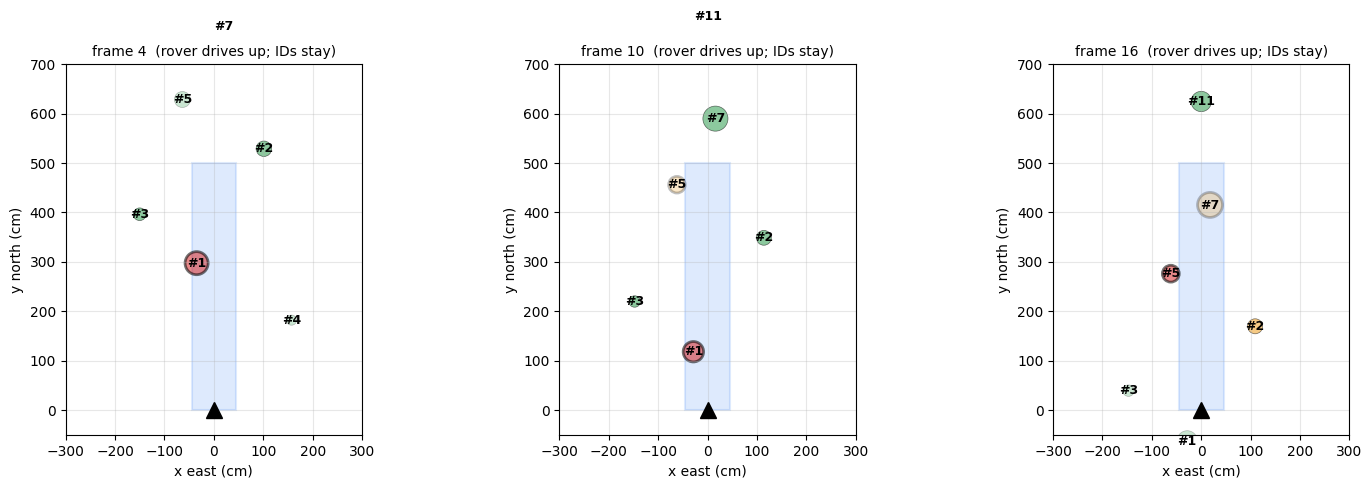

In [24]:
# 3.6 DEMO B - consecutive frames: same rock keeps its ID
# The dataset renders are NOT a driving sequence, so we simulate one: known rock map, rover drives forward 30 cm/frame,
# noisy detections (range-dependent sigma, 15% missed, ~25% false positives, 2 cm odometry noise).
CORRIDOR = Corridor(half_width_cm=45.0, length_cm=500.0, steer_deg=0.0)   # straight corridor ahead (was defined in the missing 3.5)

WORLD = [(-30, 420, 45), (110, 650, 30), (-150, 520, 25), (20, 900, 50), (160, 300, 20), (-60, 760, 35), (0, 1100, 40)]  # x, y, size (cm)

def simulate_sequence(n=24, speed=30.0, seed=7, miss=0.15, fp_rate=0.25):
    rng = np.random.default_rng(seed); seq = []
    for k in range(n):
        truth = Pose(0.0, speed * k, 0.0); dets, gt = [], []
        for i, (wx, wy, sz) in enumerate(WORLD):
            x, y = world_to_rel(truth, wx, wy)
            if not (100 < y < 900 and abs(np.degrees(np.arctan2(x, y))) < HFOV_DEG / 2) or rng.random() < miss: continue
            sig = 2 + 0.012 * y
            dets.append((Detection(0, 5, round(x + rng.normal(0, sig), 1), round(y + rng.normal(0, sig), 1), k * 100, round(sig, 1)), sz * (1 + rng.normal(0, 0.1)))); gt.append(i)
        if rng.random() < fp_rate:
            dets.append((Detection(0, 2, round(rng.uniform(-200, 200), 1), round(rng.uniform(150, 700), 1), k * 100, 15.0), 25.0)); gt.append(-1)
        seq.append((k * 100, Pose(rng.normal(0, 2), speed * k + rng.normal(0, 2), 0.0), dets, gt))
    return seq

seq = simulate_sequence()
tracker = HazardTracker(min_hits=2); log, rock_ids = [], {}
for ts, pose, dets, gt in seq:
    tracks, assign = tracker.update(pose, dets)
    log.append((ts, enrich(tracks, CORRIDOR, ts)))
    for j, g in enumerate(gt):
        if g >= 0: rock_ids.setdefault(g, set()).add(assign[j])
switches = sum(len(v) - 1 for v in rock_ids.values())
print("true rocks seen:", len(rock_ids), "| ID switches (extra IDs per real rock):", switches,
      "| IDs per rock:", {k: sorted(v) for k, v in sorted(rock_ids.items())})

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axs, (4, 10, 16)):
    draw_bev(ax, [r for r in log[k][1] if r.confirmed], CORRIDOR, f"frame {k}  (rover drives up; IDs stay)")
plt.tight_layout(); plt.show()

In [25]:
# 3.7 ENRICHED RECORD FOR PERSON B (+ export) and the live entry point
import collections
recs_all = [r for _, rs in log for r in rs if r.confirmed]
print("risk label counts (confirmed tracks, all frames):", dict(collections.Counter(r.risk for r in recs_all)))
ex = next(r for r in recs_all if r.risk == "HIGH") if any(r.risk == "HIGH" for r in recs_all) else recs_all[0]
print("example enriched record sent to Person B:"); print(json.dumps(asdict(ex), indent=1))
with open("/kaggle/working/enriched_for_B.jsonl", "w") as fh:
    for ts, rs in log:
        for r in rs:
            if r.confirmed: fh.write(json.dumps(asdict(r)) + "\n")
print("wrote /kaggle/working/enriched_for_B.jsonl")

# LIVE USE (replace the simulator): call once per camera frame with the rover pose from odometry
LIVE_TRACKER = HazardTracker(min_hits=2)
def perceive_track(frame_bgr, t_ms, pose=Pose(), corridor=CORRIDOR):
    ext = detect_b_ext(frame_bgr, t_ms)
    tracks, _ = LIVE_TRACKER.update(pose, [(d, s) for d, s, _ in ext])
    return [r for r in enrich(tracks, corridor, t_ms) if r.confirmed]

risk label counts (confirmed tracks, all frames): {'MEDIUM': 27, 'LOW': 68, 'HIGH': 26}
example enriched record sent to Person B:
{
 "class_id": 0,
 "conf": 5,
 "x_cm": -29.5,
 "y_cm": 328.8,
 "ts_ms": 300,
 "sigma_cm": 5.0,
 "track_id": 1,
 "risk": "HIGH",
 "risk_score": 0.656,
 "in_corridor": true,
 "size_cm": 43.1,
 "dist_cm": 330.1,
 "hits": 3,
 "confirmed": true,
 "observed": false
}
wrote /kaggle/working/enriched_for_B.jsonl


---
# TODO avant la partie XAI (retours du relecteur)

**1. La démo sur image réelle a disparu.** La cellule 3.5 n'est plus dans le notebook (il reste 3.4, puis 3.6). Sans elle, il n'y a plus l'étape « une image lunaire avec les rochers détectés, leur ID et le couloir ». Remettre la version de remplacement, l'exécuter et envoyer le tableau qu'elle imprime. Aucun résultat de cette cellule n'a encore été vu.
> ⚠️ `CORRIDOR` est utilisé en 3.6 / 3.7 mais n'est défini nulle part dans le notebook actuel (il l'était sûrement en 3.5). Le redéfinir tant que 3.5 n'est pas restaurée.

**2. Les vraies valeurs de la caméra.** Hauteur, inclinaison et champ de vision sont toujours les valeurs provisoires (100 cm, 10°, 70°). Tant qu'elles ne sont pas remplacées, `x_cm` et `y_cm` ne sont pas fiables, ni les distances et tailles qui servent au risque. Les demander à la personne B, avec la pose du rover et le repère voulu (relatif au point d'atterrissage).

**3. La preuve du calcul spatial (15 % de la note, le jury interrogera dessus).** Il faut : la dérivation pixel → sol, l'hypothèse de sol plat, l'explication du `sigma_cm`, et un test qui projette des points connus et les retrouve.

**4. L'efficacité des ressources (dans les 15 % de la perception).** Il n'y a que les FPS (13,3). Ajouter la taille du modèle, la RAM, l'usage CPU, et la vitesse avec 1 ou 2 threads.


---
# PHASE 4 - Explainable AI: *why* was this hazard chosen / ranked this way?
The risk score of Phase 3 is a **weighted sum** of four terms, so it can be explained **exactly** (no approximation, no SHAP needed):

| Tool | Question it answers |
|---|---|
| **Feature attribution** | How many points of the score come from corridor overlap / proximity / size / uncertainty? |
| **Counterfactuals** | What minimal change would lower the label (move aside, smaller, less uncertain)? |
| **Plain-language reason** | One sentence the operator / jury can read. |
| **Detection-level evidence** | Why was it called a rock / pit / bright patch (YOLO confidence or the rule values)? |

Run after 3.7 (needs `RISK_CFG`, `Corridor`, `CORRIDOR`, `assess`, `log`).
Caveat: this explains the **heuristic**, it does not make the heuristic a validated safety prediction.


In [26]:
# 4.1 EXACT EXPLANATION OF THE RISK SCORE (same logic as assess(), but returns the parts)
FEATURES = ["corridor overlap", "proximity", "size", "uncertainty"]

def _parts(x, y, size, sigma, corridor, cfg=RISK_CFG):
    along, lat = corridor.along_lateral(x, y)
    r = size / 2 + sigma
    clearance = abs(lat) - r - corridor.half_width_cm
    ahead = (along > -r) and (along < corridor.length_cm + r)
    inside = bool(ahead and clearance < 0)
    near = float(np.clip(1 - max(clearance, 0) / cfg["near_margin_cm"], 0, 1)) if ahead else 0.0
    dist = float(np.hypot(x, y))
    if along < -r:
        return dict(behind=True, inside=False, score=0.0, label="LOW", dist=dist, along=along, lat=lat,
                    clearance=clearance, raw=dict.fromkeys(FEATURES, 0.0), pts=dict.fromkeys(FEATURES, 0.0))
    raw = {"corridor overlap": 1.0 if inside else 0.5 * near,
           "proximity": float(np.clip(1 - dist / cfg["range_cm"], 0, 1)),
           "size": float(np.clip(size / cfg["size_ref_cm"], 0, 1)),
           "uncertainty": float(np.clip(sigma / cfg["sigma_ref_cm"], 0, 1))}
    wts = dict(zip(FEATURES, (cfg["w_overlap"], cfg["w_prox"], cfg["w_size"], cfg["w_unc"])))
    pts = {k: wts[k] * raw[k] for k in FEATURES}
    score = sum(pts.values())
    label = "HIGH" if score >= cfg["high"] else "MEDIUM" if (score >= cfg["medium"] or inside) else "LOW"
    return dict(behind=False, inside=inside, score=float(score), label=label, dist=dist, along=along, lat=lat,
                clearance=clearance, raw=raw, pts=pts)

def explain_risk(x, y, size, sigma, corridor=None, cfg=RISK_CFG):
    corridor = corridor or CORRIDOR
    base = _parts(x, y, size, sigma, corridor, cfg)
    a = np.radians(corridor.steer_deg); rgt = np.array([np.cos(a), -np.sin(a)])

    # counterfactuals: change ONE thing, recompute with the very same rule
    cf = []
    if not base["behind"]:
        if base["clearance"] < cfg["near_margin_cm"]:
            shift = cfg["near_margin_cm"] - base["clearance"]
            s = 1.0 if base["lat"] >= 0 else -1.0
            nx, ny = x + s * shift * rgt[0], y + s * shift * rgt[1]
            cf.append((f"hazard were {shift:.0f} cm further from the corridor edge", _parts(nx, ny, size, sigma, corridor, cfg)))
        cf.append(("position error were 0 cm", _parts(x, y, size, 0.0, corridor, cfg)))
        cf.append(("hazard were half as wide", _parts(x, y, size / 2, sigma, corridor, cfg)))
        cf.append(("hazard were 100 cm further away", _parts(x, y + 100, size, sigma, corridor, cfg)))
    cf = [dict(change=c, score=p["score"], label=p["label"], flips=p["label"] != base["label"]) for c, p in cf]

    # one-sentence reason
    if base["behind"]:
        text = "Already behind the rover along the planned path -> LOW, no longer a hazard."
    else:
        top = sorted(base["pts"].items(), key=lambda kv: -kv[1])[:2]
        why_in = ("it overlaps the travel corridor" if base["inside"]
                  else f"it clears the corridor by {base['clearance']:.0f} cm")
        text = (f"{base['label']} (score {base['score']:.2f}): {why_in}, {base['dist']:.0f} cm away, "
                f"~{size:.0f} cm wide, position error +/-{sigma:.0f} cm. "
                f"Main drivers: {top[0][0]} ({top[0][1]:.2f} pts) and {top[1][0]} ({top[1][1]:.2f} pts).")
        if base["inside"] and base["label"] == "MEDIUM":
            text += " Floor rule: inside the corridor => at least MEDIUM, whatever the score."
    return dict(base=base, counterfactuals=cf, text=text)

# --- consistency check: the explanation must reproduce assess() exactly
rng = np.random.default_rng(0)
for _ in range(500):
    x, y, sz, sg = rng.uniform(-250, 250), rng.uniform(-100, 800), rng.uniform(10, 80), rng.uniform(1, 60)
    ins, sc, lab, _ = assess(x, y, sz, sg, CORRIDOR)
    e = _parts(x, y, sz, sg, CORRIDOR)
    assert abs(e["score"] - sc) < 1e-9 and e["label"] == lab and e["inside"] == ins, (x, y, sz, sg)
print("OK: explanation == assess() on 500 random hazards (score, label, in_corridor)")


OK: explanation == assess() on 500 random hazards (score, label, in_corridor)


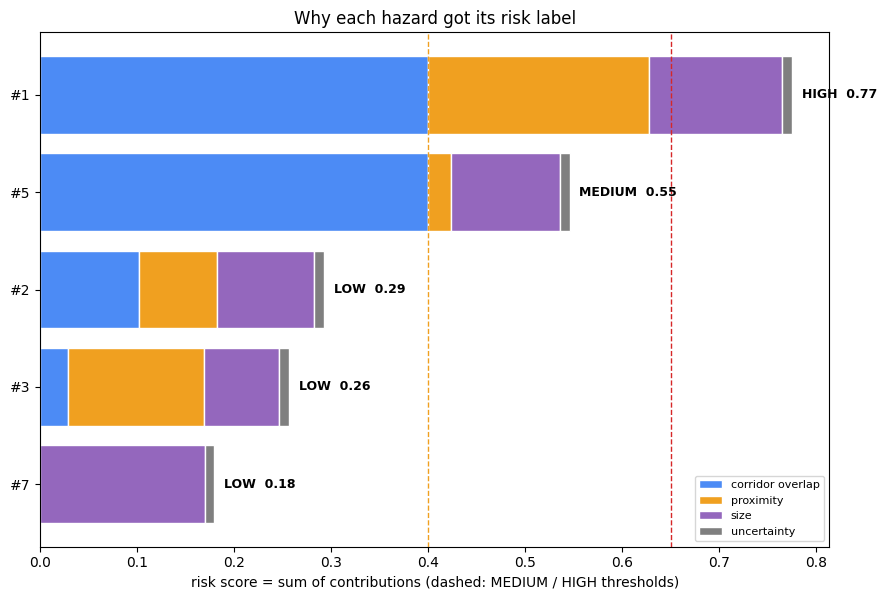


#1  HIGH (score 0.77): it overlaps the travel corridor, 121 cm away, ~41 cm wide, position error +/-5 cm. Main drivers: corridor overlap (0.40 pts) and proximity (0.23 pts).
   detection: rock: fine-tuned YOLOv8n, confidence 5/7 (~0.71). Learned detector, so no rule thresholds to show.
   what-if hazard were 142 cm further from the corridor edge: LOW (0.32)   <- label changes
   what-if position error were 0 cm: HIGH (0.76)
   what-if hazard were half as wide: HIGH (0.71)
   what-if hazard were 100 cm further away: HIGH (0.72)

#5  MEDIUM (score 0.55): it overlaps the travel corridor, 460 cm away, ~34 cm wide, position error +/-5 cm. Main drivers: corridor overlap (0.40 pts) and size (0.11 pts). Floor rule: inside the corridor => at least MEDIUM, whatever the score.
   detection: rock: fine-tuned YOLOv8n, confidence 5/7 (~0.71). Learned detector, so no rule thresholds to show.
   what-if hazard were 105 cm further from the corridor edge: LOW (0.13)   <- label changes
   what-if positi

In [27]:
# 4.2 DETECTION-LEVEL EVIDENCE: why is it a rock / pit / bright patch?
def explain_detection(cls_id, conf7, box=None, gray=None):
    if cls_id == 0:
        return f"rock: fine-tuned YOLOv8n, confidence {conf7}/7 (~{conf7/7:.2f}). Learned detector, so no rule thresholds to show."
    if cls_id == 2:
        return "bright patch (ice candidate): rule - mean grey level > 200 and solidity > 0.8."
    return "pit: rule - circularity > 0.75, area > 1% of frame, and mean grey level < 0.7 x ground mean."

# 4.3 EXPLAIN THE TOP HAZARDS OF A FRAME + STACKED-BAR FIGURE
def explain_frame(recs, corridor=None, top=5, show=True):
    corridor = corridor or CORRIDOR
    recs = sorted(recs, key=lambda r: -r.risk_score)[:top]
    exps = [explain_risk(r.x_cm, r.y_cm, r.size_cm, r.sigma_cm, corridor) for r in recs]
    if show:
        fig, ax = plt.subplots(figsize=(9, 0.9 * len(recs) + 1.6))
        colors = ["#4c8bf5", "#f0a020", "#9467bd", "#7f7f7f"]
        for i, (r, e) in enumerate(zip(recs, exps)):
            left = 0
            for k, c in zip(FEATURES, colors):
                v = e["base"]["pts"][k]
                ax.barh(i, v, left=left, color=c, label=k if i == 0 else None, edgecolor="white")
                left += v
            ax.text(left + 0.01, i, f"{e['base']['label']}  {e['base']['score']:.2f}", va="center", fontsize=9, weight="bold")
        ax.axvline(RISK_CFG["medium"], ls="--", c="#f0a020", lw=1); ax.axvline(RISK_CFG["high"], ls="--", c="#d62728", lw=1)
        ax.set_yticks(range(len(recs))); ax.set_yticklabels([f"#{r.track_id}" for r in recs]); ax.invert_yaxis()
        ax.set_xlabel("risk score = sum of contributions (dashed: MEDIUM / HIGH thresholds)")
        ax.set_title("Why each hazard got its risk label"); ax.legend(loc="lower right", fontsize=8)
        plt.tight_layout(); plt.show()
    for r, e in zip(recs, exps):
        print(f"\n#{r.track_id}  {e['text']}")
        print("   detection:", explain_detection(r.class_id, r.conf))
        for c in e["counterfactuals"]:
            print(f"   what-if {c['change']}: {c['label']} ({c['score']:.2f})" + ("   <- label changes" if c["flips"] else ""))
    return exps

# demo on a frame of the simulated drive (3.6); confirmed tracks only
k = 10
_ = explain_frame([r for r in log[k][1] if r.confirmed], CORRIDOR)


In [3]:
!ls -la /kaggle/working
!find / -type d -name delivery_for_B 2>/dev/null


total 12820
drwxr-xr-x 7 root root    4096 Oct 11 01:40 .
drwxr-xr-x 5 root root    4096 Oct 11 01:40 ..
-rw-r--r-- 1 root root 6484074 Oct 11 01:40 best.pt
drwxr-xr-x 2 root root    4096 Oct 11 01:40 data
-rw-r--r-- 1 root root   10092 Oct 11 01:40 detections_for_B.jsonl
-rw-r--r-- 1 root root   29688 Oct 11 01:40 enriched_for_B.jsonl
-rw-r--r-- 1 root root     144 Oct 11 01:40 perception_metrics_finetuned.json
-rw-r--r-- 1 root root     200 Oct 11 01:40 perception_metrics.json
drwxr-xr-x 4 root root    4096 Oct 11 01:40 runs
-rw-r--r-- 1 root root     489 Oct 11 01:40 state.db
drwxr-xr-x 2 root root    4096 Oct 11 01:40 .virtual_documents
drwxr-xr-x 2 root root    4096 Oct 11 01:40 weights
drwxr-xr-x 4 root root    4096 Oct 11 01:40 yolo_rocks
-rw-r--r-- 1 root root 6549796 Oct 11 01:40 yolov8n.pt


In [13]:
!cd /kaggle/working && zip delivery_for_B.zip best.pt detections_for_B.jsonl enriched_for_B.jsonl perception_metrics_finetuned.json

updating: best.pt (deflated 9%)
updating: detections_for_B.jsonl (deflated 84%)
updating: enriched_for_B.jsonl (deflated 90%)
updating: perception_metrics_finetuned.json (deflated 21%)


In [14]:
   !unzip -l /kaggle/working/delivery_for_B.zip

Archive:  /kaggle/working/delivery_for_B.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
  6484074  2026-10-11 01:40   best.pt
    10092  2026-10-11 01:40   detections_for_B.jsonl
    29688  2026-10-11 01:40   enriched_for_B.jsonl
      144  2026-10-11 01:40   perception_metrics_finetuned.json
---------                     -------
  6523998                     4 files
